Ciarra Barnett


## Part 1: 
1a

In [1]:
import matplotlib.pyplot as plt  
import pandas as pd 
import numpy as np 
import json 
import os 
import textwrap  


cylinders
3      4
4    199
5      3
6     83
8    103
Name: count, dtype: int64


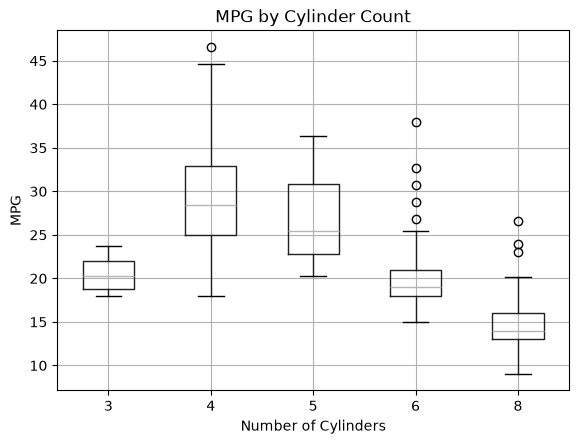

In [2]:
auto = pd.read_csv("data/Auto.csv", na_values="?").dropna().reset_index(drop=True)
print(auto["cylinders"].value_counts().sort_index())

auto.boxplot(column="mpg", by="cylinders")

plt.xlabel("Number of Cylinders")
plt.ylabel("MPG")
plt.title("MPG by Cylinder Count")
plt.suptitle("")
plt.show()


Most cars have 4,6,8 cylinders. Car with fewer cylinders generally have higher MPG, while cars with 8 cylinders tend to have the lowest

## 1b.

In [3]:
auto["cyl_rollup"] = auto["cylinders"].apply(lambda x: "< 6 cylinders" if x < 6 else "6 cylinders" if x == 6 else "8 cylinders")

auto["cyl_rollup"].value_counts()

cyl_rollup
< 6 cylinders    206
8 cylinders      103
6 cylinders       83
Name: count, dtype: int64

206 + 103 + 83 = 392 which means it it being categorized corrrectly. 

# 1c. 



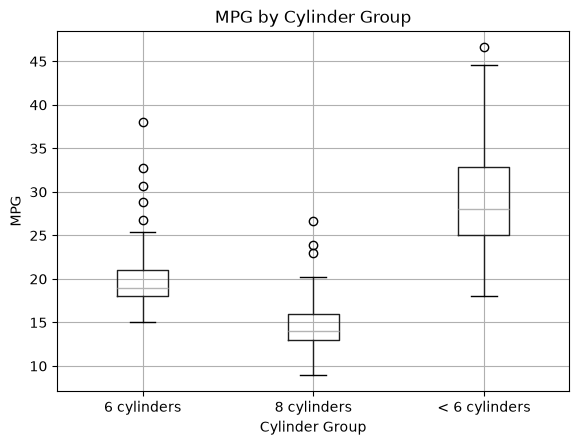

In [4]:
auto.boxplot(column="mpg", by="cyl_rollup")

plt.xlabel("Cylinder Group")
plt.ylabel("MPG")
plt.title("MPG by Cylinder Group")
plt.suptitle("")
plt.show()

Cars with < 6 cylinders have the highest MGP. 6 cylinder notes have lower MGP, and 8 cylinder cars have the lowest. MGP decreases as the number of cylinder increases 

## 1d. 

name should be excluded because it mainly serves as an identifier and contains too many unique values to be useful for prediction 

# 2a


In [5]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import KFold

In [6]:
features = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[features]
y = auto["mpg"] 

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=features)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [7]:
model = LinearRegression()
for k in range(1, 5):
    sfs = SequentialFeatureSelector(
        model,
        n_features_to_select=k,
        direction="forward",
        cv=kf
    )
    sfs.fit(X_scaled, y)
    selected_features = X_scaled.columns[sfs.get_support()]
    print(f"k = {k}: {list(selected_features)}")

k = 1: ['weight']
k = 2: ['weight', 'year']
k = 3: ['displacement', 'weight', 'year']
k = 4: ['displacement', 'horsepower', 'weight', 'year']


## 2b.

In [8]:
sfs_forward_3 = SequentialFeatureSelector(model,n_features_to_select=3,direction="forward",cv=kf)

sfs_forward_3.fit(X_scaled, y)

forward_features = X_scaled.columns[sfs_forward_3.get_support()]

sfs_backward = SequentialFeatureSelector(model,n_features_to_select=3,direction="backward",cv=kf)

sfs_backward.fit(X_scaled, y)

backward_features = X_scaled.columns[sfs_backward.get_support()]

print("Forward selection:", list(forward_features))
print("Backward selection:", list(backward_features))

Forward selection: ['displacement', 'weight', 'year']
Backward selection: ['displacement', 'weight', 'year']


Forward and bakward selection pick them same three features displacement, weight and year. This does not guarantee the best possible model becaus this method does not test each possible combinations 

## 2c. 

In [9]:
auto[["displacement", "horsepower", "weight"]].corr() 

,displacement,horsepower,weight
displacement,1.000000,0.897257,0.932994
horsepower,0.897257,1.000000,0.864538
weight,0.932994,0.864538,1.000000


In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = auto[["displacement", "horsepower", "weight"]]

vif = pd.DataFrame()
vif["Feature"] = X_vif.columns
vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif

,Feature,VIF
0,displacement,10.310539
1,horsepower,5.287295
2,weight,7.957383


Displacement, horsepower, and weight are highly related, so they give similar information. Because of this, backward selection may remove one, and forward selection may only choose one or two since the others do not add much new information

## Part 2: 1a


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

In [12]:
import os
print(os.getcwd())
print(os.listdir())

/Users/ciarrabarn/DS6021_F26
['uu_kde', '.DS_Store', 'requirements.txt', 'uv.lock', 'environment.yml', 'Lab 5.ipynb', 'pyproject.toml', 'refresh-env-files.sh', 'README.md', 'Lab2.ipynb', '.gitignore', 'homework', '.python-version', 'Lab 5.html', 'Lab 5.pdf', '.git', 'Lab1.ipynb', 'data', 'in_class_notebooks']


In [13]:
import pandas as pd

auto = pd.read_csv("data/Auto.csv", na_values="?").dropna().reset_index(drop=True)

In [14]:
num_A = ["displacement", "weight", "year"]

X_A = auto[num_A]
y = auto["mpg"]

model_A = make_pipeline(StandardScaler(),LinearRegression())

X_train_A, X_test_A, y_train, y_test = train_test_split( X_A, y, test_size=0.2, random_state=42)

model_A.fit(X_train_A, y_train)

train_rmse_A = root_mean_squared_error(y_train, model_A.predict(X_train_A))

test_rmse_A = root_mean_squared_error(y_test, model_A.predict(X_test_A))

print(f"Model A training RMSE: {train_rmse_A:.3f}")
print(f"Model A testing RMSE: {test_rmse_A:.3f}")

Model A training RMSE: 3.460
Model A testing RMSE: 3.261


In [15]:
auto["cyl_rollup"] = np.where(
    auto["cylinders"] < 6,
    "< 6 cylinders",
    np.where(
        auto["cylinders"] == 6,
        "6 cylinders",
        "8 cylinders"
    )
)
auto[["cylinders", "cyl_rollup"]].head()

,cylinders,cyl_rollup
0,8,8 cylinders
1,8,8 cylinders
2,8,8 cylinders
3,8,8 cylinders
4,8,8 cylinders


In [16]:
num_B = ["displacement", "weight", "year"]
cat_B = ["cyl_rollup", "origin"]
X_B = auto[num_B + cat_B]
y = auto["mpg"]

preprocess_B = make_column_transformer(
    (StandardScaler(), num_B),
    (OneHotEncoder(drop="first", sparse_output=False), cat_B),
    remainder="drop",
    verbose_feature_names_out=False
)

model_B = make_pipeline(
    preprocess_B,
    LinearRegression()
)

X_train_B, X_test_B, y_train_B, y_test_B = train_test_split(
    X_B,
    y,
    test_size=0.2,
    random_state=42
)


model_B.fit(X_train_B, y_train_B)

train_rmse_B = root_mean_squared_error(
    y_train_B,
    model_B.predict(X_train_B)
)

test_rmse_B = root_mean_squared_error(
    y_test_B,
    model_B.predict(X_test_B)
)

print("Model B Training RMSE:", round(train_rmse_B, 3))
print("Model B Testing RMSE:", round(test_rmse_B, 3))

Model B Training RMSE: 3.226
Model B Testing RMSE: 3.089


In [17]:
results = pd.DataFrame({"Model": ["Model A", "Model B"],"Train RMSE": [train_rmse_A, train_rmse_B],"Test RMSE": [test_rmse_A, test_rmse_B]})
results.round(3)

,Model,Train RMSE,Test RMSE
0,Model A,3.460,3.261
1,Model B,3.226,3.089


# 1b. 
Model B is better because it has a lower test RMSE than Model A. This means Model B predicts MPG more accurately on unseen data 

# 2a. 

In [18]:
from sklearn.model_selection import KFold, cross_val_score

In [19]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
cv10 = KFold(n_splits=10, shuffle=True, random_state=42)

In [20]:
A_5_rmse = -cross_val_score(model_A,X_A,y,cv=cv5,scoring="neg_root_mean_squared_error").mean()

A_10_rmse = -cross_val_score(model_A,X_A,y,cv=cv10,scoring="neg_root_mean_squared_error").mean()

B_5_rmse = -cross_val_score(model_B,X_B,y,cv=cv5,scoring="neg_root_mean_squared_error").mean()

B_10_rmse = -cross_val_score(model_B,X_B,y,cv=cv10,scoring="neg_root_mean_squared_error").mean()


print(f"Model A 5-fold RMSE: {A_5_rmse:.3f}")
print(f"Model A 10-fold RMSE: {A_10_rmse:.3f}")
print(f"Model B 5-fold RMSE: {B_5_rmse:.3f}")
print(f"Model B 10-fold RMSE: {B_10_rmse:.3f}")

Model A 5-fold RMSE: 3.422
Model A 10-fold RMSE: 3.391
Model B 5-fold RMSE: 3.235
Model B 10-fold RMSE: 3.205


In [21]:
cv_results = pd.DataFrame({"Model": ["Model A", "Model B"],"Train/Test RMSE": [test_rmse_A, test_rmse_B],"5-Fold RMSE": [A_5_rmse, B_5_rmse],"10-Fold RMSE": [A_10_rmse, B_10_rmse]})
cv_results.round(3)

,Model,Train/Test RMSE,5-Fold RMSE,10-Fold RMSE
0,Model A,3.261,3.422,3.391
1,Model B,3.089,3.235,3.205


## 2b. 
The results are similar across all three methods. Cross validation gives slightly higher RMSE values than the single train/test split, but Model B still performs better every time. The 5 fold and 10 fold RMSE values are very close, showing that the results are consistent

## 2c. 
Model B is better because it has a lower RMSE for the train/test split, 5-fold cv, and 10-fold cv. This suggest that adding cyl_rollup and orgin improves the ability to predict MPG 

## 3. 

In [22]:
def cv_rmse(model, X, y, method):
    mse = -cross_val_score(
        model,
        X,
        y,
        cv=method,
        scoring="neg_mean_squared_error"
    )
    return np.sqrt(mse.mean())

In [23]:
rows = []
for seed in range(100):

    X_train_A, X_test_A, y_train_A, y_test_A = train_test_split(X_A, y, test_size=0.2, random_state=seed)

    model_A.fit(X_train_A, y_train_A)

    rows += [
        {
            "model": "Model A",
            "method": "Train/test",
            "seed": seed,
            "rmse": root_mean_squared_error(
                y_test_A,
                model_A.predict(X_test_A)
            )
        },
        {
            "model": "Model A",
            "method": "5-fold",
            "seed": seed,
            "rmse": cv_rmse(
                model_A,
                X_A,
                y,
                KFold(n_splits=5, shuffle=True, random_state=seed)
            )
        },
        {
            "model": "Model A",
            "method": "10-fold",
            "seed": seed,
            "rmse": cv_rmse(
                model_A,
                X_A,
                y,
                KFold(n_splits=10, shuffle=True, random_state=seed)
            )
        }
    ]


    X_train_B, X_test_B, y_train_B, y_test_B = train_test_split(
        X_B, y, test_size=0.2, random_state=seed
    )

    model_B.fit(X_train_B, y_train_B)

    rows += [
        {
            "model": "Model B",
            "method": "Train/test",
            "seed": seed,
            "rmse": root_mean_squared_error(
                y_test_B,
                model_B.predict(X_test_B)
            )
        },
        {
            "model": "Model B",
            "method": "5-fold",
            "seed": seed,
            "rmse": cv_rmse(
                model_B,
                X_B,
                y,
                KFold(n_splits=5, shuffle=True, random_state=seed)
            )
        },
        {
            "model": "Model B",
            "method": "10-fold",
            "seed": seed,
            "rmse": cv_rmse(
                model_B,
                X_B,
                y,
                KFold(n_splits=10, shuffle=True, random_state=seed)
            )
        }
    ]

by_seed = pd.DataFrame(rows)

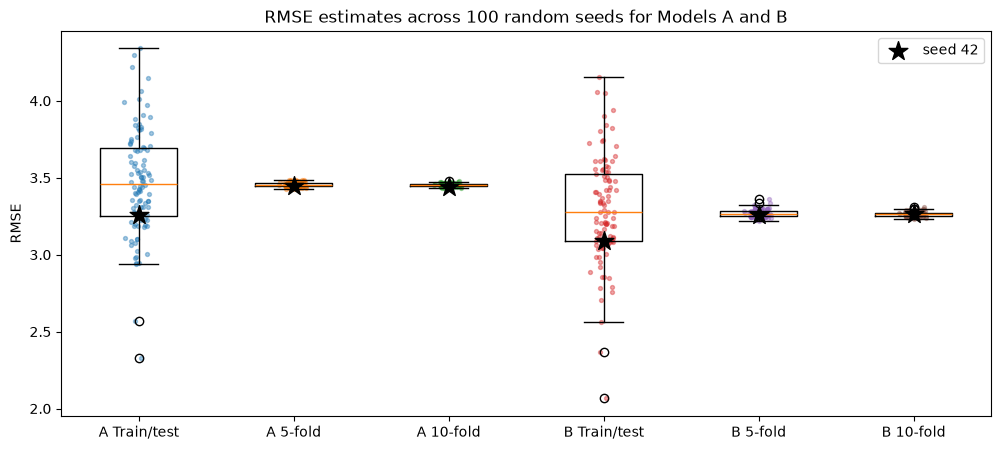

In [24]:
order = [
    "A Train/test",
    "A 5-fold",
    "A 10-fold",
    "B Train/test",
    "B 5-fold",
    "B 10-fold"
]

by_seed["group"] = by_seed["model"].str[-1] + " " + by_seed["method"]

fig, ax = plt.subplots(figsize=(12, 5))

ax.boxplot(
    [
        by_seed.loc[by_seed.group == g, "rmse"]
        for g in order
    ],
    tick_labels=order
)

for i, g in enumerate(order, start=1):
    vals = by_seed.loc[by_seed.group == g, "rmse"]

    ax.scatter(
        np.random.default_rng(0).normal(i, 0.04, len(vals)),
        vals,
        s=8,
        alpha=0.4
    )

    ax.scatter(
        i,
        by_seed.loc[
            (by_seed.group == g) &
            (by_seed.seed == 42),
            "rmse"
        ],
        marker="*",
        s=200,
        color="black",
        zorder=3,
        label="seed 42" if i == 1 else None
    )

ax.set(
    ylabel="RMSE",
    title="RMSE estimates across 100 random seeds for Models A and B"
)

ax.legend()
plt.show()

In [25]:
by_seed.groupby(["model", "method"])["rmse"].agg(["mean", "std", "min", "max"]).round(3)

mean    std    min    max
model   method                                
Model A 10-fold     3.454  0.009  3.431  3.482
        5-fold      3.456  0.014  3.427  3.485
        Train/test  3.472  0.344  2.331  4.340
Model B 10-fold     3.264  0.014  3.235  3.307
        5-fold      3.269  0.024  3.222  3.364
        Train/test  3.292  0.349  2.066  4.157

# 3a. 

I would choose Model B because it consistently has a lower RSME than Model A across 100 random seeds. Model B has lower average RMSE values for train/test splits, 5-fold cv, 10- fold cv which predicts MGP and it performs better 

## 3b. 
Yes, the categorical variables are worth adding because Model B has lower RMSE than Model A. Adding cyl_rollup and origin makes the predictions more accurate across all three methods 

## Part 3 
1a. 


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.metrics import root_mean_squared_error

In [27]:
bike = pd.read_csv("data/bike-sharing-daily.csv")

In [28]:
x1 = bike[["temp"]].values
yy = bike["cnt"].values

grid = np.linspace(x1.min(), x1.max(), 200)[:, None]

x1_tr, x1_te, y1_tr, y1_te = train_test_split(x1,yy,test_size=0.2,random_state=2345)

In [29]:
model_A = LinearRegression().fit(x1_tr, y1_tr)
model_B = make_pipeline(StandardScaler(),PolynomialFeatures(9, include_bias=False),LinearRegression()).fit(x1_tr, y1_tr)
model_C = make_pipeline(SplineTransformer(degree=3,n_knots=7,knots="quantile"),LinearRegression()).fit(x1_tr, y1_tr)

def rmse(model, X, y):return root_mean_squared_error(y, model.predict(X))
print(f"Model A test RMSE: {rmse(model_A, x1_te, y1_te):.2f}")
print(f"Model B test RMSE: {rmse(model_B, x1_te, y1_te):.2f}")
print(f"Model C test RMSE: {rmse(model_C, x1_te, y1_te):.2f}")

Model A test RMSE: 1549.08
Model B test RMSE: 1594.58
Model C test RMSE: 1417.98


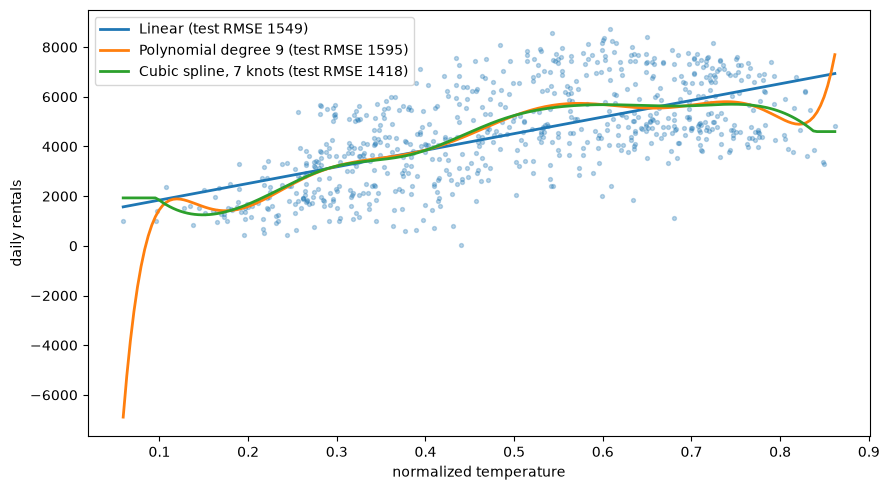

In [30]:
plt.figure(figsize=(9, 5))

plt.scatter(x1, yy, s=8, alpha=0.3)

plt.plot(
    grid,
    model_A.predict(grid),
    lw=2,
    label=f"Linear (test RMSE {rmse(model_A, x1_te, y1_te):.0f})"
)

plt.plot(
    grid,
    model_B.predict(grid),
    lw=2,
    label=f"Polynomial degree 9 (test RMSE {rmse(model_B, x1_te, y1_te):.0f})"
)

plt.plot(
    grid,
    model_C.predict(grid),
    lw=2,
    label=f"Cubic spline, 7 knots (test RMSE {rmse(model_C, x1_te, y1_te):.0f})"
)

plt.xlabel("normalized temperature")
plt.ylabel("daily rentals")
plt.legend()
plt.tight_layout()
plt.show()

## 1d. 

Model C which is the cubic spline, performs best because it has the lowest test RMSE. The linear model is simple while degree -9 polynomial is too flexible and becomes unstable at ends 

## 2a. 

Model B has the lowest training RMSE, while Model C has the lowest test RMSE 

# 2b. 
No. A lower training RMSE does not always mean a lower test RMSE. Model B has the lowest training error, but Model C has the lowest test error 

# 2c. 

Model B shows some overfitting because it is very flexible and has worse test performance. Model A may underfit because it is too simple, while Model C gives the best balance 

# 3. 

In [31]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

In [32]:
cv5 = KFold(n_splits=5,shuffle=True,random_state=2345)

In [33]:
def evaluate_model(model, X, y):

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    cv_rmse = -cross_val_score(model,X,y,cv=5,scoring="neg_root_mean_squared_error").mean()

    return train_rmse, test_rmse, cv_rmse
print(X_B.dtypes)


displacement    float64
weight            int64
year              int64
cyl_rollup          str
origin            int64
dtype: object


In [34]:
A_results = evaluate_model(model_A, x1, yy)
B_results = evaluate_model(model_B, x1, yy)
C_results = evaluate_model(model_C, x1, yy)

In [35]:
results = pd.DataFrame({
    "Model": ["Model A", "Model B", "Model C"],

    "Training RMSE": [
        A_results[0],
        B_results[0],
        C_results[0]
    ],

    "Testing RMSE": [
        A_results[1],
        B_results[1],
        C_results[1]
    ],

    "5-Fold RMSE": [
        A_results[2],
        B_results[2],
        C_results[2]
    ]
})

results.round(2)

,Model,Training RMSE,Testing RMSE,5-Fold RMSE
0,Model A,1497.67,1546.30,1834.7
1,Model B,1379.26,1531.56,1826.1
2,Model C,1380.57,1532.43,1766.7


Yes, cross validation gives me more confidence because it tests the models on multiple data splits. Model C has the lowest 5 fold RMSE, so it performs best overall. Model B has a lower training RMSE but a higher cv RMSE 

# Part 4

1a. 

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_train, X_test, y_train, y_test = train_test_split(
    x1,
    yy,
    test_size=0.2,
    random_state=2345
)

X_train = np.asarray(X_train)
y_train = np.asarray(y_train)

B = 500
rng = np.random.default_rng(42)

x0 = np.array([[0.60]])

pred_A = []
pred_B = []
pred_C = []

for b in range(B):

  
    idx = rng.choice(
        len(X_train),
        size=len(X_train),
        replace=True
    )

    X_boot = X_train[idx]
    y_boot = y_train[idx]

    boot_A = clone(model_A)
    boot_B = clone(model_B)
    boot_C = clone(model_C)

    boot_A.fit(X_boot, y_boot)
    boot_B.fit(X_boot, y_boot)
    boot_C.fit(X_boot, y_boot)


    pred_A.append(boot_A.predict(x0)[0])
    pred_B.append(boot_B.predict(x0)[0])
    pred_C.append(boot_C.predict(x0)[0])

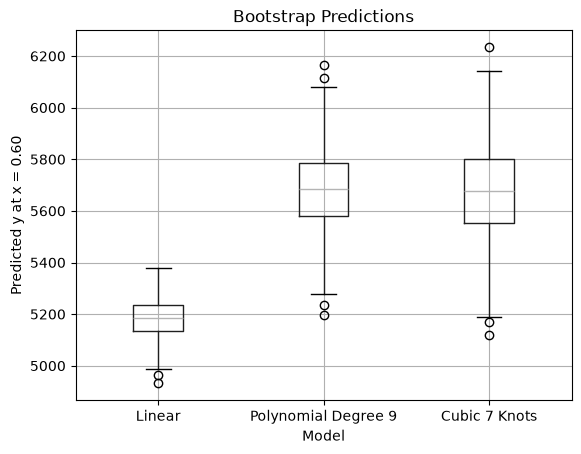

In [37]:
bootstrap_results = pd.DataFrame({"Linear": pred_A,"Polynomial Degree 9": pred_B,"Cubic 7 Knots": pred_C})

bootstrap_results.boxplot()

plt.xlabel("Model")
plt.ylabel("Predicted y at x = 0.60")
plt.title("Bootstrap Predictions")
plt.show()

In [38]:
bootstrap_results.std()

Linear                  71.730935
Polynomial Degree 9    157.671281
Cubic 7 Knots          186.968422
dtype: float64

## 1a. 

The linear model is the most stable, while the cubic 7 knots model is the most variable. This is shown by the smaller spread for linear and the larger spread for the cubic model

## 1b. 

The linear model is the most stable, and the spline model is the most variable. More flexible models can be more sensitive to the training data

## 1c. 
If predictions change a lot across samples, the model has high variance. It may be overfitting and may not work as well on new data

# 2a. 
The linear model is the most stable but also the least flexible. The polynomial and spline models fit the data better, but their predictions vary more. The polynomial shows some signs of overfitting, while the spline has the most variability but also the best test and cv performance meaning it has the best overall balance 

# 2b. 
The lowest training RMSE does not always mean the best model. A flexible model can have low bias but high variance and overfit. A good model should also perform well on new data 

AI Disclosure: 


I used AI to help explain concepts in detail that I did not understand and debug code. I also used the Week 5, 6, and 7 lecture slides and class notebooks as references to make sure my work followed the methods and concepts taught in class